In [1]:
import pandas as pd
import numpy as np

# Load the dataset created by your script
# We use parse_dates to ensure 'Datetime' is treated as a time object, not a string
df = pd.read_csv('malaysia_solar_hourly_analytics.csv', parse_dates=['Datetime'])

print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.")



Dataset loaded successfully with 1315080 rows and 16 columns.


In [2]:
# Show column names and data types
print(df.dtypes)
print("\n")
# More complete summary
print(df.info())

Datetime                  datetime64[us]
State                                str
Latitude                         float64
Longitude                        float64
GHI_W_m2                         float64
DNI_W_m2                         float64
DHI_W_m2                         float64
Cloud_Coverage_Pct               float64
Temp_Air_2m_C                    float64
Temp_Skin_C                      float64
Relative_Humidity_Pct            float64
Surface_Pressure_kPa             float64
Wind_Speed_10m_m_s               float64
Wind_Direction_10m_deg           float64
Precipitable_Water_cm            float64
Rainfall_mm                      float64
dtype: object


<class 'pandas.DataFrame'>
RangeIndex: 1315080 entries, 0 to 1315079
Data columns (total 16 columns):
 #   Column                  Non-Null Count    Dtype         
---  ------                  --------------    -----         
 0   Datetime                1315080 non-null  datetime64[us]
 1   State                   1315080 non

In [3]:
# Check how many -999.0 values exist in each column
nasa_missing_counts = (df == -999.0).sum()

print("NASA Missing Values (-999.0) by Column:")
print(nasa_missing_counts[nasa_missing_counts > 0]) # Only show columns that actually have -999.0

NASA Missing Values (-999.0) by Column:
GHI_W_m2    360
DNI_W_m2    360
DHI_W_m2    360
dtype: int64


In [4]:
# Replace NASA's fill value with standard numpy NaN
df.replace(-999.0, np.nan, inplace=True)

# Now check the true missing data across the whole dataset
print("True Missing Data Count After Conversion:")
missing_summary = df.isnull().sum()
print(missing_summary[missing_summary > 0])

# Calculate the percentage of missing data
missing_percentage = (missing_summary / len(df)) * 100
print("\nPercentage of Missing Data:")
print(missing_percentage[missing_percentage > 0].round(2).astype(str) + '%')

True Missing Data Count After Conversion:
GHI_W_m2    360
DNI_W_m2    360
DHI_W_m2    360
dtype: int64

Percentage of Missing Data:
GHI_W_m2    0.03%
DNI_W_m2    0.03%
DHI_W_m2    0.03%
dtype: str


In [5]:
# Isolate the rows where data is missing
missing_data = df[df['GHI_W_m2'].isnull()]

# Count how many states are missing data at each exact Datetime
missing_by_time = missing_data.groupby('Datetime').size()

print(f"Total unique hours missing data: {len(missing_by_time)}")

print("\nFrequency of missing data across states:")
# This tells us if the outage hit 1 state, or all 16 states at once
print(missing_by_time.value_counts().rename_axis('Number of States Affected').reset_index(name='Count of Hours'))

print("\nExact Timestamps of the Outage (Showing first 10):")
print(missing_by_time.head(10))

Total unique hours missing data: 24

Frequency of missing data across states:
   Number of States Affected  Count of Hours
0                         15              24

Exact Timestamps of the Outage (Showing first 10):
Datetime
2025-12-31 00:00:00    15
2025-12-31 01:00:00    15
2025-12-31 02:00:00    15
2025-12-31 03:00:00    15
2025-12-31 04:00:00    15
2025-12-31 05:00:00    15
2025-12-31 06:00:00    15
2025-12-31 07:00:00    15
2025-12-31 08:00:00    15
2025-12-31 09:00:00    15
dtype: int64


In [6]:
# Drop the 384 rows (the 24 hours on Dec 31, 2025 across all 16 states)
df.dropna(inplace=True)

# Verify the dataset is now 100% clean
print(f"Missing values remaining: {df.isnull().sum().sum()}")
print(f"Total rows remaining: {len(df):,}")

Missing values remaining: 0
Total rows remaining: 1,314,720


In [7]:
import pandas as pd
# Missing value count
print("True Missing Data Count After Conversion:")
missing_summary = df.isnull().sum()

if (missing_summary > 0).any():
    print(missing_summary[missing_summary > 0])
else:
    print("0")

# Missing percentage
print("\nPercentage of Missing Data:")
missing_percentage = (missing_summary / len(df)) * 100
if (missing_percentage > 0).any():
    print(missing_percentage[missing_percentage > 0].round(2).astype(str) + '%')
else:
    print("0%")

True Missing Data Count After Conversion:
0

Percentage of Missing Data:
0%


In [8]:
# Count how many exact duplicate rows exist
total_duplicates = df.duplicated().sum()
print(f"Total exact duplicates: {total_duplicates}")

Total exact duplicates: 0


In [9]:
# 1. Ensure the 'Hour' column exists
if 'Hour' not in df.columns:
    df['Hour'] = df['Datetime'].dt.hour
    print("Created missing 'Hour' column.")

# 2. Recreate Is_Daylight with correct logic (FORCE OVERWRITE)
df['Is_Daylight'] = ((df['Hour'] >= 6) & (df['Hour'] <= 17)).astype(int)
print("Updated 'Is_Daylight' column with hours 6-17.")

# Verify
print("\nFirst 11 rows with updated Is_Daylight:")
print(df[['Datetime', 'Hour', 'GHI_W_m2', 'Is_Daylight']].head(23))

Created missing 'Hour' column.
Updated 'Is_Daylight' column with hours 6-17.

First 11 rows with updated Is_Daylight:
              Datetime  Hour  GHI_W_m2  Is_Daylight
0  2016-01-01 00:00:00     0      0.00            0
1  2016-01-01 01:00:00     1      0.00            0
2  2016-01-01 02:00:00     2      0.00            0
3  2016-01-01 03:00:00     3      0.00            0
4  2016-01-01 04:00:00     4      0.00            0
5  2016-01-01 05:00:00     5      0.00            0
6  2016-01-01 06:00:00     6     21.52            1
7  2016-01-01 07:00:00     7    104.75            1
8  2016-01-01 08:00:00     8    232.73            1
9  2016-01-01 09:00:00     9    333.42            1
10 2016-01-01 10:00:00    10    276.67            1
11 2016-01-01 11:00:00    11    354.62            1
12 2016-01-01 12:00:00    12    287.25            1
13 2016-01-01 13:00:00    13    180.30            1
14 2016-01-01 14:00:00    14    180.90            1
15 2016-01-01 15:00:00    15    121.55            

In [10]:
## Save the cleared na file
df.to_csv('malaysia_solar_hourly_analytics_clean.csv', index=False)


## Data Preprocessing

In [11]:
import pandas as pd
import numpy as np

df = pd.read_csv('malaysia_solar_hourly_analytics_clean.csv', parse_dates=['Datetime'])
print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.")

Dataset loaded successfully with 1314720 rows and 18 columns.


# Drop DNI & DHI

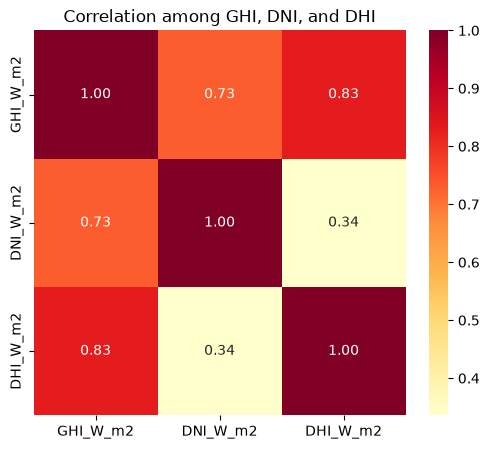

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

daylight_df = df[df['Is_Daylight'] == 1].copy()

corr_cols = ['GHI_W_m2', 'DNI_W_m2', 'DHI_W_m2']
corr_matrix = daylight_df[corr_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='YlOrRd', fmt='.2f')
plt.title('Correlation among GHI, DNI, and DHI')
plt.show()

In [13]:
df.drop(columns=['DHI_W_m2'], inplace=True)
df.drop(columns=['DNI_W_m2'], inplace=True)
print(df.dtypes)

Datetime                  datetime64[us]
State                                str
Latitude                         float64
Longitude                        float64
GHI_W_m2                         float64
Cloud_Coverage_Pct               float64
Temp_Air_2m_C                    float64
Temp_Skin_C                      float64
Relative_Humidity_Pct            float64
Surface_Pressure_kPa             float64
Wind_Speed_10m_m_s               float64
Wind_Direction_10m_deg           float64
Precipitable_Water_cm            float64
Rainfall_mm                      float64
Hour                               int64
Is_Daylight                        int64
dtype: object


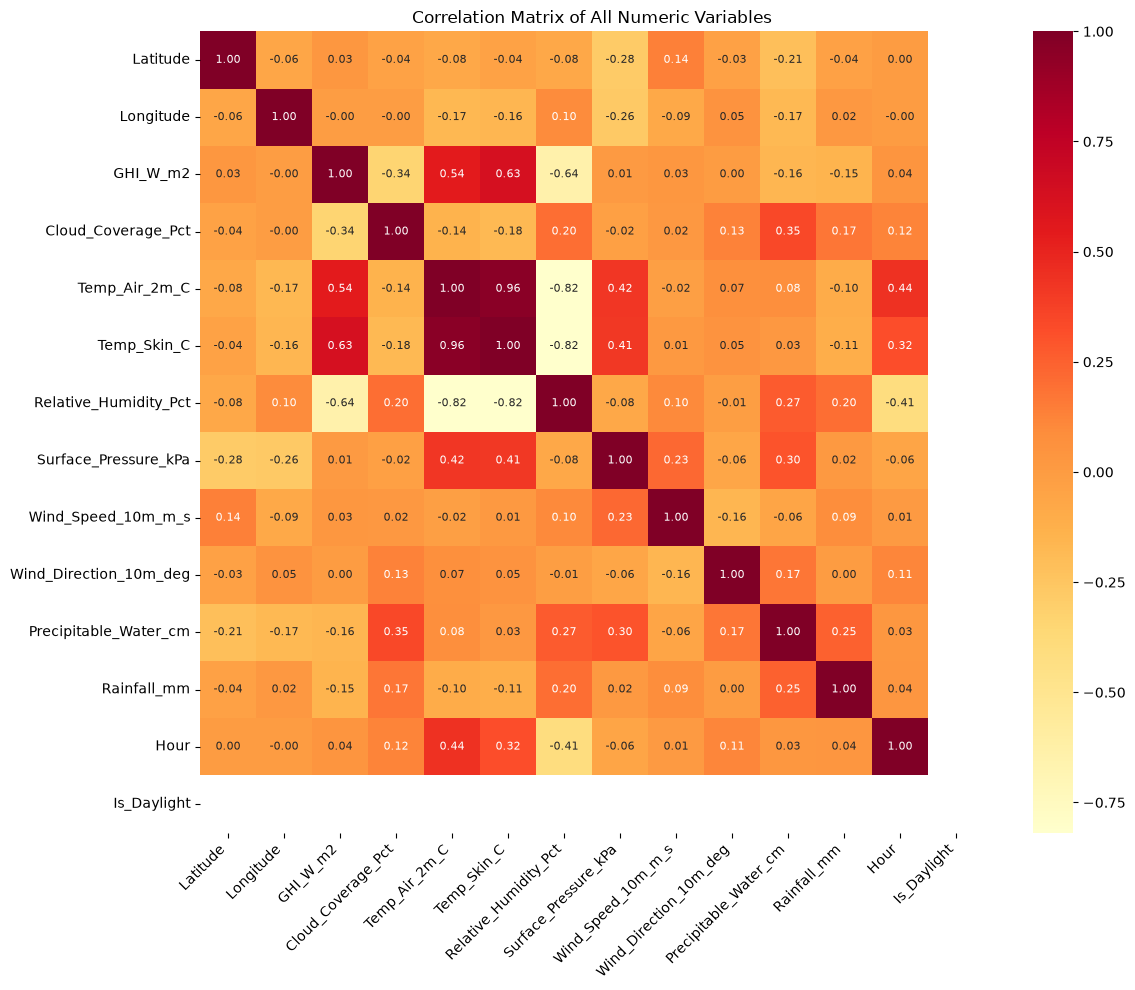

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


daylight_df = df[df['Is_Daylight'] == 1].copy()

numeric_cols = daylight_df.select_dtypes(include=[np.number])

corr_matrix = numeric_cols.corr()

plt.figure(figsize=(12, 10)) 

sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='YlOrRd', 
    fmt='.2f',
    annot_kws={"size": 8} 
)

plt.title('Correlation Matrix of All Numeric Variables')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [15]:
df.drop(columns=['Temp_Air_2m_C'], inplace=True)
print(df.dtypes)

Datetime                  datetime64[us]
State                                str
Latitude                         float64
Longitude                        float64
GHI_W_m2                         float64
Cloud_Coverage_Pct               float64
Temp_Skin_C                      float64
Relative_Humidity_Pct            float64
Surface_Pressure_kPa             float64
Wind_Speed_10m_m_s               float64
Wind_Direction_10m_deg           float64
Precipitable_Water_cm            float64
Rainfall_mm                      float64
Hour                               int64
Is_Daylight                        int64
dtype: object


In [16]:
## Save the cleared na file
df.to_csv('malaysia_solar_hourly_analytics_prepared.csv', index=False)

In [17]:
import pandas as pd
import numpy as np

df = pd.read_csv('malaysia_solar_hourly_analytics_prepared.csv', parse_dates=['Datetime'])
print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.")

# Show column names and data types
print(df.dtypes)
print("\n")
# More complete summary
print(df.info())

Dataset loaded successfully with 1314720 rows and 15 columns.
Datetime                  datetime64[us]
State                                str
Latitude                         float64
Longitude                        float64
GHI_W_m2                         float64
Cloud_Coverage_Pct               float64
Temp_Skin_C                      float64
Relative_Humidity_Pct            float64
Surface_Pressure_kPa             float64
Wind_Speed_10m_m_s               float64
Wind_Direction_10m_deg           float64
Precipitable_Water_cm            float64
Rainfall_mm                      float64
Hour                               int64
Is_Daylight                        int64
dtype: object


<class 'pandas.DataFrame'>
RangeIndex: 1314720 entries, 0 to 1314719
Data columns (total 15 columns):
 #   Column                  Non-Null Count    Dtype         
---  ------                  --------------    -----         
 0   Datetime                1314720 non-null  datetime64[us]
 1   State         